# 02 · K-Means: who are GroupBuy's buyers?
**Business problem:** campaigns and messages cannot be identical for everyone. A price hunter who will wait 10 days needs a different offer from a convenience buyer.

**Why clustering:** there are no predefined segment labels, and K-Means finds groups of similar respondents using behaviour alone. Intent answers (section G) and the conversion score are deliberately left out so we can test afterwards whether segments differ in intent.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
BLUE,ORANGE,AQUA,YELLOW='#2a78d6','#eb6834','#1baf7a','#eda100'
FIG='../Results/figures/'; SEED=42
c=pd.read_csv('../Dataset/customers.csv')
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
FEATS=['A7_Monthly_Income_AED','A6_Household_Size','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','C1_Price_Consciousness','C2_Willing_To_Wait_For_Deal','C3_Trust_New_Platforms','C4_Social_Influence','C5_Convenience_Priority','C7_Values_Price_Transparency','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days']
X=c[FEATS].copy()
for col in ['A7_Monthly_Income_AED','B1_Monthly_Spend_Eligible_AED']: X[col]=np.log1p(X[col])  # money is right-skewed
Z=make_pipeline(SimpleImputer(strategy='median'),StandardScaler()).fit_transform(X)  # scaling stops AED columns dominating 1-5 ratings

## Choosing k

 k   inertia  silhouette
 2 11738.347       0.296
 3  9905.794       0.229
 4  8501.886       0.227
 5  7544.113       0.237
 6  7386.657       0.202
 7  7230.435       0.168
 8  7086.716       0.123
 9  6972.881       0.094


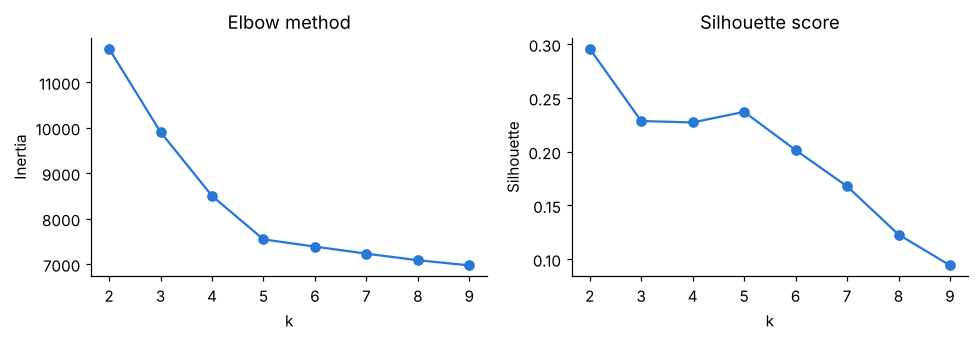

chosen k 5 | silhouette 0.237


In [2]:
rows=[]
for k in range(2,10):
    km=KMeans(k,n_init=20,random_state=SEED).fit(Z); rows.append(dict(k=k,inertia=km.inertia_,silhouette=silhouette_score(Z,km.labels_)))
ev=pd.DataFrame(rows); ev.to_csv('../Results/Clustering_K_Selection.csv',index=False); print(ev.round(3).to_string(index=False))
fig,a=plt.subplots(1,2,figsize=(9,3.2))
a[0].plot(ev.k,ev.inertia,marker='o',color=BLUE); a[0].set(title='Elbow method',xlabel='k',ylabel='Inertia')
a[1].plot(ev.k,ev.silhouette,marker='o',color=BLUE); a[1].set(title='Silhouette score',xlabel='k',ylabel='Silhouette')
plt.tight_layout(); plt.savefig(FIG+'clustering_k.png'); plt.show()
K=5; print('chosen k',K,'| silhouette',ev.set_index('k').silhouette[K].round(3))

**Decision:** silhouette peaks at k=2, but that split only separates wealthy convenience buyers from everyone else, which is too coarse to act on. k=5 is the elbow (inertia almost stops falling after it) and a clear local silhouette peak. Silhouette of about 0.24 means segments overlap: they are useful groupings, not sharply separated types.

In [3]:
km=KMeans(K,n_init=20,random_state=SEED).fit(Z); c['Cluster']=km.labels_
prof=c.groupby('Cluster').agg(Customers=('Customer_ID','size'),Income=('A7_Monthly_Income_AED','median'),Spend=('B1_Monthly_Spend_Eligible_AED','median'),Orders=('B2_Online_Orders_Per_Month','mean'),SME_Share=('Is_SME','mean'),Price=('C1_Price_Consciousness','mean'),Wait=('C2_Willing_To_Wait_For_Deal','mean'),Trust=('C3_Trust_New_Platforms','mean'),Social=('C4_Social_Influence','mean'),Convenience=('C5_Convenience_Priority','mean'),Min_Discount=('F1_Min_Discount_To_Switch_Pct','mean'),Max_Wait=('F2_Max_Wait_Days','mean'),Max_Delivery_Fee=('B6_Max_Delivery_Fee_AED','mean'),Order_Value=('G4_Expected_Order_Value_AED','median'),Conversion_Score=('Conversion_Score_0to10','mean'),High_Intent_Share=('Conversion_Segment',lambda s:(s=='High').mean())).round(2)
print(prof.T.to_string())

Cluster                   0         1         2         3         4
Customers            288.00    231.00    165.00    220.00    296.00
Income             15700.00  17250.00  26500.00  48950.00  13800.00
Spend               1580.00   1800.00   7580.00   4220.00   2650.00
Orders                 8.71      1.83      5.84     11.91      5.14
SME_Share              0.00      0.00      0.94      0.00      0.01
Price                  3.93      3.57      4.21      2.08      4.45
Wait                   3.01      2.81      3.67      1.76      3.86
Trust                  3.69      1.80      3.45      3.49      3.48
Social                 4.29      2.32      2.61      2.74      3.83
Convenience            3.77      2.57      3.18      4.55      2.79
Min_Discount          14.97     21.98      9.54     24.97     12.10
Max_Wait               5.02      4.07      9.83      2.10      6.90
Max_Delivery_Fee       9.99      7.13     23.75     30.34      8.00
Order_Value          350.00    260.00   1720.00 

## Interpreting and naming the segments
Names are assigned by reading the profile above.

variance shown by 2 PCA axes 0.471


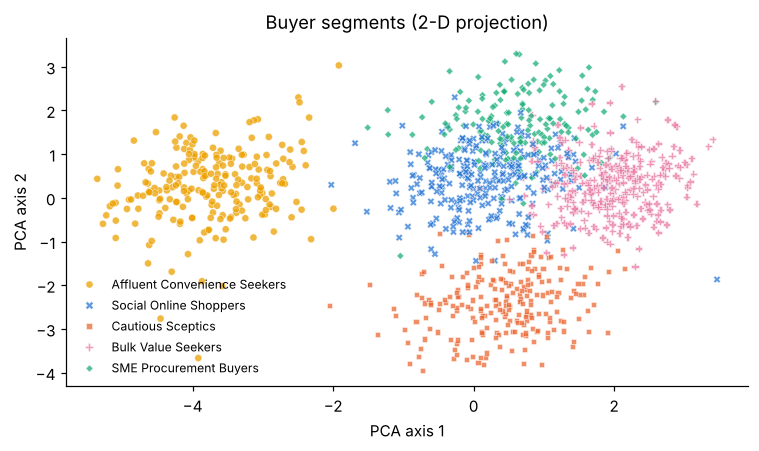

                              Segment  Customers  High_Intent_Share  Order_Value
Cluster                                                                         
0              Social Online Shoppers        288               0.22        350.0
1                   Cautious Sceptics        231               0.04        260.0
2              SME Procurement Buyers        165               0.45       1720.0
3        Affluent Convenience Seekers        220               0.04        590.0
4                  Bulk Value Seekers        296               0.59        685.0


In [4]:
names={0:'Social Online Shoppers',1:'Cautious Sceptics',2:'SME Procurement Buyers',3:'Affluent Convenience Seekers',4:'Bulk Value Seekers'}
strategy={0:'Recruit through referral rewards and WhatsApp groups; run small-basket, short campaigns.',1:'Do not spend paid acquisition; nurture with verified-savings proof and refund guarantees.',2:'Prioritise for high-value office and bulk campaigns; offer bid comparison and VAT invoices.',3:'Exclude from standard campaigns; test only premium, fast-delivery offers.',4:'Core launch audience: staples and household campaigns with consolidated delivery.'}
c['Segment']=c.Cluster.map(names); p2=PCA(2,random_state=SEED).fit(Z); xy=p2.transform(Z); print('variance shown by 2 PCA axes',p2.explained_variance_ratio_.sum().round(3))
c.assign(PC1=xy[:,0].round(3),PC2=xy[:,1].round(3))[['Customer_ID','Cluster','Segment','PC1','PC2']].to_csv('../Results/Customer_Segments.csv',index=False)
prof.insert(0,'Segment',prof.index.map(names)); prof['Strategy']=prof.index.map(strategy); prof.to_csv('../Results/Cluster_Profiles.csv')
pal=dict(zip(names.values(),[BLUE,ORANGE,AQUA,YELLOW,'#e87ba4']))
fig,ax=plt.subplots(figsize=(7,4.2))
sns.scatterplot(x=xy[:,0],y=xy[:,1],hue=c.Segment,style=c.Segment,palette=pal,s=22,ax=ax,alpha=.75); ax.set(xlabel='PCA axis 1',ylabel='PCA axis 2',title='Buyer segments (2-D projection)'); ax.legend(fontsize=8,frameon=False); plt.tight_layout(); plt.savefig(FIG+'clusters_pca.png'); plt.show()
print(prof[['Segment','Customers','High_Intent_Share','Order_Value']].to_string())